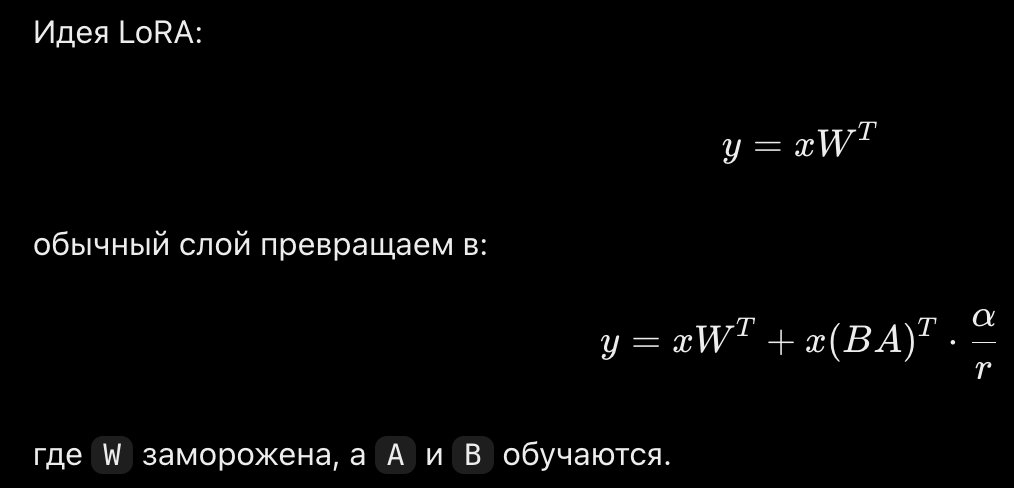

In [1]:
import torch
import torch.nn as nn

class LoRALinear(nn.Module):
    def __init__(self, in_features, out_features, rank=4, alpha=8):
        super().__init__()

        ## обычная большая матрица весов
        self.linear = nn.Linear(in_features, out_features, bias=False)

        ## Замораживаем базовые веса
        self.linear.weight.requires_grad = False

        ##LoRA
        self.A = nn.Parameter(torch.randn(rank, in_features) * 0.01) ## добавляем новый параметр в модель

        self.B = nn.Parameter(torch.zeros(out_features, rank))

        self.scale = alpha / rank

    def forward(self, x):
        ## замороженный слой
        base_output = self.linear(x)

        ## LoRA
        lora_output = (x @ self.A.T @ self.B.T)
        return base_output + self.scale * lora_output

In [ ]:
## допустим

layer = LoRALinear(
    in_features=768,
    out_features=768,
    rank=8
)

## Исходная матрица W: 768 × 768 = 589 824 параметра

## А вот LoRA: матрица A = 8 × 768, матрица B = 768 × 8, получится: 8×768 + 768×8 = 12 288 параметров

In [2]:
layer = LoRALinear(
    in_features=4,
    out_features=3,
    rank=2
)

optimizer = torch.optim.Adam(
    filter(
        lambda p: p.requires_grad,
        layer.parameters()
    ),
    lr=1e-2
)

x = torch.randn(10, 4)
target = torch.randn(10, 3)

before_W = layer.linear.weight.clone()

for step in range(100):
    optimizer.zero_grad()

    pred = layer(x)

    loss = ((pred - target) ** 2).mean()

    loss.backward()
    optimizer.step()

In [3]:
torch.allclose(
    before_W,
    layer.linear.weight
)

True

In [4]:
print(layer.A)
print(layer.B)

Parameter containing:
tensor([[ 0.4835,  0.0176, -0.2442,  0.3794],
        [-0.2079,  0.3973,  0.4067,  0.3761]], requires_grad=True)
Parameter containing:
tensor([[-0.1478,  0.4089],
        [ 0.2255, -0.2171],
        [-0.2701, -0.2980]], requires_grad=True)


W вообще не изменилась!
